In [11]:
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import matplotlib as mpl

from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder

# Plot formatting
cm = 0.3937008
mpl.rcParams["figure.dpi"] = 300
mpl.rcParams["figure.figsize"] = (8*cm, 5*cm)
mpl.rcParams["lines.linewidth"] = 0.2
mpl.rcParams["font.size"] = 5
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["errorbar.capthick"] = 0.2
mpl.rcParams["errorbar.capsize"] = 1.5
mpl.rcParams["lines.markersize"] = 0.1

In [12]:
def FindSource(hdu):
    """
    Find the centre of the brightest source in an image.

    Returns:
        source: centre coordinates in image coords
        factor: conversion factor from image to detector coords 
    """

    # Taking the data and conversion factor between image and detector coords
    data = hdu.data
    factor = hdu.header["CDELT1L"]

    # Detecting sources
    mean, median, std = sigma_clipped_stats(data, sigma=3.0)
    daofind = DAOStarFinder(fwhm=3.0, threshold=1*std)
    sources = daofind(data - median)

    # Taking the brightest source detected
    source = sources[sources["mag"] == sources["mag"].min()]

    source = np.array([source["x_centroid"].data[0], source["y_centroid"].data[0]])

    return source, factor

def PlotSelection(hdu, source, factor, radii):
    """
    Plot the image and detected centre

    Returns:
        fig, ax: The produced figure and axis objects
    """

    fig, ax = plt.subplots()

    # Plotting the image
    ax.imshow(hdu.data, origin='lower', norm=LogNorm(), cmap="plasma")

    # Cropping to the small window
    ax.set_xlim(source[0] - 1.1*radii[2], source[0] + 1.1*radii[2])
    ax.set_ylim(source[1] - 1.1*radii[2], source[1] + 1.1*radii[2])

    # Removing ticks
    ax.set_xticks([])
    ax.set_yticks([])

    # Plotting circles for region selections
    ax.add_patch(plt.Circle(source, radii[0], color='lime', fill=False, lw=1))
    ax.add_patch(plt.Circle(source, radii[1], color='lime', fill=False, lw=1))
    ax.add_patch(plt.Circle(source, radii[2], color='lime', fill = False, lw=1))

    return fig, ax

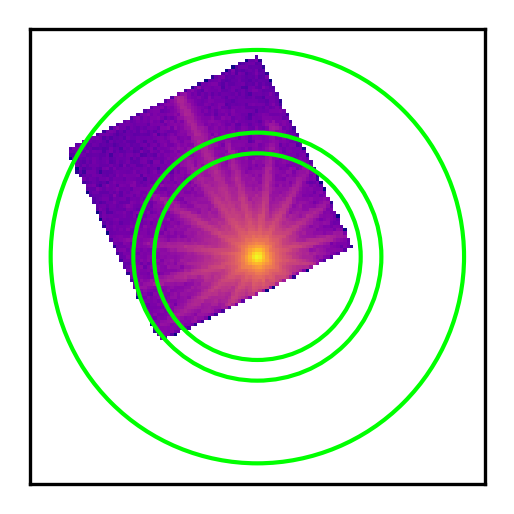

In [13]:
# Opening the file
hdu = fits.open("../data/pn-all.fits")[0]

# Finding the source
source, factor = FindSource(hdu)

# Plotting the detection
fig, ax = PlotSelection(hdu, source, factor, [2500/factor, 3000/factor, 5000/factor])